In [ ]:
import sys
from pathlib import Path


sys.path.insert(0, str(Path.cwd().parent))

from cartera.db import conectar
from cartera.valoracion import rentabilidades_totales, rentabilidad_twr
from cartera.riesgo import tabla_riesgo

conn = conectar()

In [2]:
cartera_id_demo = conn.execute("SELECT id FROM carteras WHERE nombre = 'Demo';").fetchone()[0]
cartera_id_demo

1

In [3]:
activos = rentabilidades_totales(conn, ["BBVA.MC", "JPM", "KO", "REP.MC", "TEF.MC"])
benchmark = rentabilidades_totales(conn, ["URTH"])["URTH"]
cartera = rentabilidad_twr(conn, cartera_id_demo)

todo = activos.assign(Cartera=cartera, URTH=benchmark)
tabla_riesgo(todo, benchmark).round(3)

,rent_anual,vol_anual,sharpe,sortino,max_drawdown,beta,correlacion,tracking_error,ratio_informacion
BBVA.MC,0.415,0.300,1.243,1.783,1.008,0.549,0.334,0.296,1.015
JPM,0.168,0.252,0.666,0.954,1.004,0.921,0.663,0.191,0.428
KO,0.153,0.184,0.758,1.099,1.004,0.388,0.382,0.205,0.258
REP.MC,0.282,0.280,0.957,1.350,0.995,0.161,0.105,0.319,0.613
TEF.MC,0.036,0.212,0.181,0.245,0.995,0.064,0.055,0.275,-0.182
Cartera,0.380,0.145,2.161,3.236,0.996,0.377,0.420,0.168,1.203
URTH,0.101,0.183,0.506,0.732,0.981,1.000,1.000,0.000,NaN


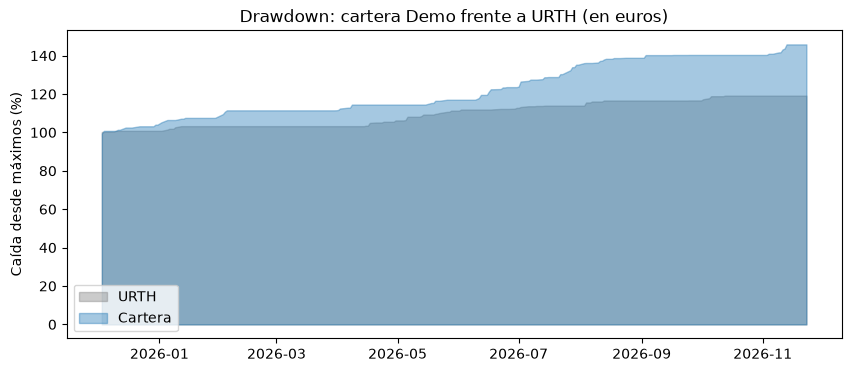

In [4]:
import matplotlib.pyplot as plt
from pathlib import Path
from cartera.riesgo import alinear, drawdowns, volatilidad_ewma

CARPETA = Path.cwd().parent / "graficos"
CARPETA.mkdir(exist_ok=True)

a = alinear(cartera, benchmark)
a.columns = ["Cartera", "URTH"]

fig, ax = plt.subplots(figsize=(10, 4))
for nombre, color in [("URTH", "tab:gray"), ("Cartera", "tab:blue")]:
    dd = drawdowns(a[nombre]) * 100
    ax.fill_between(dd.index, dd, 0, color=color, alpha=0.4, label=nombre)
ax.set_ylabel("Caída desde máximos (%)")
ax.set_title("Drawdown: cartera Demo frente a URTH (en euros)")
ax.legend(loc="lower left")
fig.savefig(CARPETA / "drawdown.png", dpi=150, bbox_inches="tight")

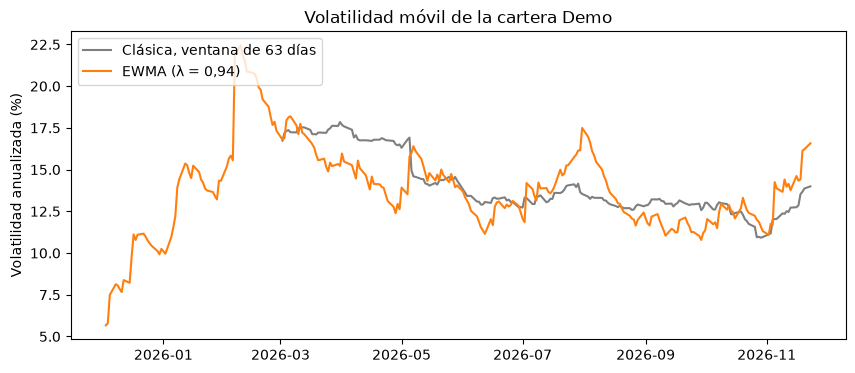

In [6]:
import numpy as np
r = cartera.dropna()
vol_ewma = volatilidad_ewma(r) * 100
vol_63 = r.rolling(63).std() * np.sqrt(252) * 100

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(vol_63.index, vol_63, label="Clásica, ventana de 63 días", color="tab:gray")
ax.plot(vol_ewma.index, vol_ewma, label="EWMA (λ = 0,94)", color="tab:orange")
ax.set_ylabel("Volatilidad anualizada (%)")
ax.set_title("Volatilidad móvil de la cartera Demo")
ax.legend(loc="upper left")
fig.savefig(CARPETA / "volatilidad.png", dpi=150, bbox_inches="tight")